In [1]:
from torch.utils.data import DataLoader, TensorDataset
import torch

# 模拟数据
data = torch.randn(100, 3, 32, 32)  # 100张 32x32 彩图
labels = torch.randint(0, 10, (100,))

dataset = TensorDataset(data, labels)

# 创建 DataLoader
dataloader = DataLoader(
    dataset=dataset,
    batch_size=16,
    shuffle=True,
    num_workers=4,          # 开启 4 个子进程
    # pin_memory=True,        # 加速 GPU 传输
    drop_last=True,         # 丢弃 100/16=6.25 中最后多出的 4 张图
    persistent_workers=True # 保持 workers 存活，节省重启时间
)

# 训练循环迭代
for epoch in range(10):
    for batch_idx, (imgs, lbls) in enumerate(dataloader):
        # imgs.shape = (16, 3, 32, 32)
        # lbls.shape = (16,)
        pass

In [1]:
#使用transformer实现手写字识别
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import math
import time

# 检查 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# -------------------- 数据准备 --------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST 的均值和标准差
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

Using device: cpu


In [14]:
class PatchEmbedding(nn.Module):
    """将图像分割成 patches 并映射为嵌入向量"""
    def __init__(self, img_size=28, patch_size=7, in_channels=1, embed_dim=64):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2  # 4x4=16

        # 使用卷积实现 patch 分割和线性投影 (kernel_size = patch_size, stride = patch_size)
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x: [B, C, H, W]
        x = self.proj(x)                # [B, embed_dim, H/patch, W/patch]
        x = x.flatten(2)                 # [B, embed_dim, num_patches]
        x = x.transpose(1, 2)            # [B, num_patches, embed_dim]
        return x

In [23]:
train_dataset[0][0].shape

torch.Size([1, 28, 28])

In [26]:
t.proj(train_dataset[0][0]).shape


torch.Size([64, 4, 4])

In [20]:
t.proj

Conv2d(1, 64, kernel_size=(7, 7), stride=(7, 7))

In [ ]:
t(train_dataset[0][0])


In [30]:
import torch
import torch.nn as nn

# 参数设置
in_channels = 1 #3
embed_dim = 768
patch_size = 16

# 模拟输入：1张 224x224 的彩色图片
x = torch.randn(1, 1, 224, 224)

# 创建卷积层
conv = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

# 前向传播
out = conv(x)

print(f"输入形状: {x.shape}")   # torch.Size([1, 3, 224, 224])
print(f"输出形状: {out.shape}") # torch.Size([1, 768, 14, 14])

# 验证 Patch 数量：224/16 = 14，所以有 14*14 = 196 个 Patch
# 输出形状 [1, 768, 14, 14] 意味着：有 196 个位置，每个位置对应一个 768 维向量。

输入形状: torch.Size([1, 1, 224, 224])
输出形状: torch.Size([1, 768, 14, 14])


In [51]:
import torch
import torch.nn as nn

# 特征维度为 256
layer_norm = nn.LayerNorm(normalized_shape=256)

# 模拟输入：批次4，序列长度10，特征维度256
x = torch.randn(4, 10, 256)
y = layer_norm(x)

print(y.shape)  # 输出 torch.Size([4, 10, 256])，形状不变！
# 验证：对最后一维计算均值，确实是 0 附近
print(y.mean(dim=-1).mean())  # 非常接近 0

torch.Size([4, 10, 256])
tensor(-6.8103e-10, grad_fn=<MeanBackward0>)


In [ ]:
# 如果输入是 [Batch, 64, 32, 32]，要对 C,H,W 做归一化
ln_cv = nn.LayerNorm(normalized_shape=[64, 32, 32])
x_cv = torch.randn(2, 64, 32, 32)
y_cv = ln_cv(x_cv)
print(y_cv.shape)  # 输出 torch.Size([2, 64, 32, 32])
# 此时，每个样本单独计算自己 [64,32,32] 所有像素的均值和方差，减去。

In [31]:
#使用transformer实现手写字识别
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import math
import time

# 检查 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# -------------------- 数据准备 --------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST 的均值和标准差
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# -------------------- Vision Transformer 模型 --------------------
class PatchEmbedding(nn.Module):
    """将图像分割成 patches 并映射为嵌入向量"""
    def __init__(self, img_size=28, patch_size=7, in_channels=1, embed_dim=64):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2  # 4x4=16

        # 使用卷积实现 patch 分割和线性投影 (kernel_size = patch_size, stride = patch_size)
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x: [B, C, H, W]
        x = self.proj(x)                # [B, embed_dim, H/patch, W/patch]
        x = x.flatten(2)                 # [B, embed_dim, num_patches]
        x = x.transpose(1, 2)            # [B, num_patches, embed_dim]
        return x

class TransformerEncoderBlock(nn.Module):
    """单个 Transformer 编码器块"""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ff = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # 自注意力 + 残差
        attn_out, _ = self.attn(self.norm1(x), self.norm1(x), self.norm1(x))
        x = x + attn_out
        # 前馈 + 残差
        ff_out = self.ff(self.norm2(x))
        x = x + ff_out
        return x

class VisionTransformer(nn.Module):
    """用于 MNIST 分类的 Vision Transformer"""
    def __init__(self, img_size=28, patch_size=7, in_channels=1, num_classes=10,
                 embed_dim=64, depth=4, num_heads=4, ff_dim=128, dropout=0.1):
        super().__init__()

        # Patch 嵌入
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # 可学习的类别令牌 (class token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        # 位置编码（可学习）
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, embed_dim))

        self.dropout = nn.Dropout(dropout)

        # Transformer 编码器
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        # 初始化权重
        self._init_weights()

    def _init_weights(self):
        # 按照 ViT 的常见初始化
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_module_weights)

    def _init_module_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        # 获取 patch 嵌入
        x = self.patch_embed(x)          # [B, num_patches, embed_dim]

        # 添加类别令牌
        cls_tokens = self.cls_token.expand(B, -1, -1)   # [B, 1, embed_dim]
        x = torch.cat([cls_tokens, x], dim=1)           # [B, num_patches+1, embed_dim]

        # 添加位置编码
        x = x + self.pos_embed
        x = self.dropout(x)

        # 通过 Transformer 块
        for block in self.blocks:
            x = block(x)

        # 提取类别令牌对应的输出
        x = self.norm(x)
        cls_out = x[:, 0]                 # [B, embed_dim]
        logits = self.head(cls_out)       # [B, num_classes]
        return logits

# -------------------- 训练和评估 --------------------
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = 100. * correct / total
    return avg_loss, acc

def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = 100. * correct / total
    return avg_loss, acc

# -------------------- 主训练循环 --------------------
model = VisionTransformer(
    img_size=28,
    patch_size=7,
    in_channels=1,
    num_classes=10,
    embed_dim=64,
    depth=4,
    num_heads=4,
    ff_dim=128,
    dropout=0.1
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.7)

num_epochs = 20
best_acc = 0

print("开始训练...")
for epoch in range(1, num_epochs + 1):
    start_time = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    test_loss, test_acc = evaluate(model, test_loader, criterion)
    scheduler.step()

    epoch_time = time.time() - start_time
    print(f"Epoch {epoch:2d}/{num_epochs} | Time: {epoch_time:.1f}s | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), "best_mnist_vit.pth")
        print(f"  -> 保存最佳模型 (准确率: {best_acc:.2f}%)")

print(f"\n训练完成！最佳测试准确率: {best_acc:.2f}%")

Using device: cpu
开始训练...
Epoch  1/20 | Time: 51.0s | Train Loss: 0.6388 | Train Acc: 79.44% | Test Loss: 0.2351 | Test Acc: 92.86%
  -> 保存最佳模型 (准确率: 92.86%)
Epoch  2/20 | Time: 50.0s | Train Loss: 0.2279 | Train Acc: 93.10% | Test Loss: 0.1647 | Test Acc: 94.90%
  -> 保存最佳模型 (准确率: 94.90%)
Epoch  3/20 | Time: 50.4s | Train Loss: 0.1724 | Train Acc: 94.61% | Test Loss: 0.1144 | Test Acc: 96.46%
  -> 保存最佳模型 (准确率: 96.46%)
Epoch  4/20 | Time: 50.3s | Train Loss: 0.1436 | Train Acc: 95.56% | Test Loss: 0.1004 | Test Acc: 96.83%
  -> 保存最佳模型 (准确率: 96.83%)
Epoch  5/20 | Time: 51.6s | Train Loss: 0.1234 | Train Acc: 96.07% | Test Loss: 0.1094 | Test Acc: 96.54%
Epoch  6/20 | Time: 50.8s | Train Loss: 0.1128 | Train Acc: 96.44% | Test Loss: 0.0966 | Test Acc: 96.99%
  -> 保存最佳模型 (准确率: 96.99%)
Epoch  7/20 | Time: 51.0s | Train Loss: 0.0997 | Train Acc: 96.80% | Test Loss: 0.0831 | Test Acc: 97.32%
  -> 保存最佳模型 (准确率: 97.32%)
Epoch  8/20 | Time: 51.3s | Train Loss: 0.0933 | Train Acc: 97.08% | Test Lo

In [1]:
# 调用已经训练过的模型：
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import math
import time

# 检查 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# -------------------- 数据准备 --------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST 的均值和标准差
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# -------------------- Vision Transformer 模型 --------------------
class PatchEmbedding(nn.Module):
    """将图像分割成 patches 并映射为嵌入向量"""
    def __init__(self, img_size=28, patch_size=7, in_channels=1, embed_dim=64):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2  # 4x4=16

        # 使用卷积实现 patch 分割和线性投影 (kernel_size = patch_size, stride = patch_size)
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x: [B, C, H, W]
        x = self.proj(x)                # [B, embed_dim, H/patch, W/patch]
        x = x.flatten(2)                 # [B, embed_dim, num_patches]
        x = x.transpose(1, 2)            # [B, num_patches, embed_dim]
        return x

class TransformerEncoderBlock(nn.Module):
    """单个 Transformer 编码器块"""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ff = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # 自注意力 + 残差
        attn_out, _ = self.attn(self.norm1(x), self.norm1(x), self.norm1(x))
        x = x + attn_out
        # 前馈 + 残差
        ff_out = self.ff(self.norm2(x))
        x = x + ff_out
        return x

class VisionTransformer(nn.Module):
    """用于 MNIST 分类的 Vision Transformer"""
    def __init__(self, img_size=28, patch_size=7, in_channels=1, num_classes=10,
                 embed_dim=64, depth=4, num_heads=4, ff_dim=128, dropout=0.1):
        super().__init__()

        # Patch 嵌入
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # 可学习的类别令牌 (class token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        # 位置编码（可学习）
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, embed_dim))

        self.dropout = nn.Dropout(dropout)

        # Transformer 编码器
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        # 初始化权重
        self._init_weights()

    def _init_weights(self):
        # 按照 ViT 的常见初始化
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_module_weights)

    def _init_module_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        # 获取 patch 嵌入
        x = self.patch_embed(x)          # [B, num_patches, embed_dim]

        # 添加类别令牌
        cls_tokens = self.cls_token.expand(B, -1, -1)   # [B, 1, embed_dim]
        x = torch.cat([cls_tokens, x], dim=1)           # [B, num_patches+1, embed_dim]

        # 添加位置编码
        x = x + self.pos_embed
        x = self.dropout(x)

        # 通过 Transformer 块
        for block in self.blocks:
            x = block(x)

        # 提取类别令牌对应的输出
        x = self.norm(x)
        cls_out = x[:, 0]                 # [B, embed_dim]
        logits = self.head(cls_out)       # [B, num_classes]
        return logits

# -------------------- 训练和评估 --------------------
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = 100. * correct / total
    return avg_loss, acc

def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = 100. * correct / total
    return avg_loss, acc

# -------------------- 主训练循环 --------------------
model = VisionTransformer(
    img_size=28,
    patch_size=7,
    in_channels=1,
    num_classes=10,
    embed_dim=64,
    depth=4,
    num_heads=4,
    ff_dim=128,
    dropout=0.1
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.7)

num_epochs = 20
best_acc = 0

# print("开始训练...")
# for epoch in range(1, num_epochs + 1):
#     start_time = time.time()
#     train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
#     test_loss, test_acc = evaluate(model, test_loader, criterion)
#     scheduler.step()

#     epoch_time = time.time() - start_time
#     print(f"Epoch {epoch:2d}/{num_epochs} | Time: {epoch_time:.1f}s | "
#           f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
#           f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

#     if test_acc > best_acc:
#         best_acc = test_acc
#         torch.save(model.state_dict(), "best_mnist_vit.pth")
#         print(f"  -> 保存最佳模型 (准确率: {best_acc:.2f}%)")

# print(f"\n训练完成！最佳测试准确率: {best_acc:.2f}%")

model.load_state_dict(torch.load('best_mnist_vit.pth', map_location='cpu'))
model.eval()
# with torch.no_grad():  # 禁止梯度计算，节约内存
#     # test_input = torch.randn(1, 10)
#     output = new_model(test_dataset)
#     print(f"预测结果（Logits）: {output}")



Using device: cpu


VisionTransformer(
  (patch_embed): PatchEmbedding(
    (proj): Conv2d(1, 64, kernel_size=(7, 7), stride=(7, 7))
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x TransformerEncoderBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)

In [2]:
i = 2
t = train_dataset[i][0]
model(t.unsqueeze(0,)),train_dataset[i][1]

(tensor([[-5.7271, -1.4971, -1.4899, -5.0091, 12.9367, -4.8171,  0.3261,  1.2836,
          -0.8297,  2.5751]], grad_fn=<AddmmBackward0>),
 4)

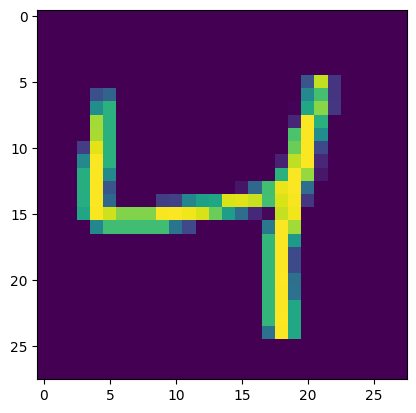

In [17]:
plt.imshow(t[0,:,:])

In [9]:
train_dataset[0][1]

5

In [6]:
t.unsqueeze(1,)

tensor([[[[-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
           -0.4242, -0.4242, -0.424